# 03 Unsupervised: Node2Vec Representation and Clustering

This notebook is the executable, thesis-facing record for the unsupervised experiment. It constructs the reconstructed Ethereum transaction graph, examines the frozen Node2Vec representation, evaluates clustering alignment with public address categories, and reports robustness across class-balanced samples, walk-bias settings, and training seeds.

The experiment contributes to **RQ2** by measuring the role information captured by graph structure before supervised classification. Node2Vec learns node representations from biased random walks followed by a skip-gram objective.


## 0. Reproducibility mode and frozen evidence

The default execution mode validates and reads the dissertation evidence in `node2vec_results/`. SHA-256 checks protect every active result table and both embedding matrices from accidental modification.

Set `RUN_RETRAINING=True` to train a fresh baseline representation. Fresh artifacts are written to `node2vec_rerun_validation/`. Set `RUN_MULTI_SEED_RETRAINING=True` as well to run the fifteen-condition p/q multi-seed experiment. The active dissertation evidence remains read-only in both modes.


In [1]:
from pathlib import Path
import hashlib
import json
import random

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.cluster import DBSCAN, KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

cwd = Path.cwd().resolve()
if cwd.name == "03_unsupervised":
    PROJECT_ROOT = cwd.parent
elif (cwd / "03_unsupervised").exists():
    PROJECT_ROOT = cwd
else:
    raise FileNotFoundError("Run this notebook from the project root or 03_unsupervised.")

UNSUPERVISED_ROOT = PROJECT_ROOT / "03_unsupervised"
RESULT_DIR = UNSUPERVISED_ROOT / "node2vec_results"
RERUN_DIR = UNSUPERVISED_ROOT / "node2vec_rerun_validation"
EDGES_FILE = PROJECT_ROOT / "00_data_graph" / "data" / "main" / "raw_edges_reconstructed.csv"
FEATURE_FILE = PROJECT_ROOT / "02_feature_engineering" / "feature_engineering" / "seed_feature_matrix_reconstructed.csv"

RUN_RETRAINING = False
RUN_MULTI_SEED_RETRAINING = False

EXPECTED_HASHES = {
    "balanced_ari_repeated_runs.csv": "13D915EC5F0904998AEFC6C5B5E11A20C49B7E78C218B721780F9C57C2296C33",
    "balanced_ari_summary.csv": "8ABE351F84BD1D4F45A5FD351040A109E6B8F40AF5ACA87E3ACAED0DAC79E11F",
    "clustering_evaluation_summary.csv": "D648FA841E139FDEFADF59987DC589089B28A9AF9AF09B78E3429CBEE2298B3A",
    "clustering_significance_test.csv": "64C4444F6E6335704F2FB3340F0CFBC32B0DA6E6A97F6D9A893D7489A34B9329",
    "dbscan_eps_scan.csv": "CB12A3C9696EB334B1EDD9C2D7F81DA904E56DCAEFBDE3BF62523BD8F1E22259",
    "kmeans_k_scan.csv": "E9F0447E52ACBEDAC40603160536BA0B80066D8D13D11BEEBBE3C5F00E2FBD9E",
    "node2vec_embeddings.csv": "20E174AC29B38C7D29581437E31E02C50677DAB306B91B2497B6BA2D8445542F",
    "pq_multiseed_checkpoint_metadata.json": "EFB947A727F43419BB4115E8CE3A80C854832DE182DC16A59DE4D02D163130F9",
    "pq_multiseed_per_seed.csv": "8AB80948B8FC201B7A79C3068027D989EFE0FA154BC46145A99F0DB85538492B",
    "pq_multiseed_summary.csv": "04FC6F5B205CEC3C51E3639B4FBF761B996E2F0800EECAB8CF88CD5E233A95D5",
    "pq_sensitivity_results.csv": "1D1CA7F644DB49D0D6BE8713632E780ECF3F58268418F670829B211D4FBBA6D8",
    "seed_node2vec_embeddings.csv": "98734F6D60062973D25B4B039862727C2AB452444AF9FCE6BC8BA103CF48A126",
}

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest().upper()

def stable_hash(value):
    payload = str(value).encode("utf-8")
    return int.from_bytes(hashlib.sha256(payload).digest()[:8], "little")

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)

if RERUN_DIR.resolve() == RESULT_DIR.resolve():
    raise RuntimeError("The rerun directory must be separate from the frozen result directory.")

hash_rows = []
for name, expected in EXPECTED_HASHES.items():
    path = RESULT_DIR / name
    actual = sha256_file(path)
    hash_rows.append({"artifact": name, "sha256_match": actual == expected})
    if actual != expected:
        raise RuntimeError(f"Frozen evidence hash mismatch: {name}")

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9", "font.size": 10,
})

display(pd.DataFrame(hash_rows))
print(f"Frozen evidence verified: {len(hash_rows)} artifacts")
print(f"Execution mode: {'isolated retraining' if RUN_RETRAINING else 'frozen evidence'}")


,artifact,sha256_match
0,balanced_ari_repeated_runs.csv,True
1,balanced_ari_summary.csv,True
2,clustering_evaluation_summary.csv,True
3,clustering_significance_test.csv,True
4,dbscan_eps_scan.csv,True
5,kmeans_k_scan.csv,True
6,node2vec_embeddings.csv,True
7,pq_multiseed_checkpoint_metadata.json,True
8,pq_multiseed_per_seed.csv,True
9,pq_multiseed_summary.csv,True


Frozen evidence verified: 12 artifacts
Execution mode: frozen evidence


## 1. Construct the transaction graph

Each input row is an aggregated directed transaction edge. `tx_count` supplies the edge weight. The experiment creates a directed graph for provenance and an undirected weighted view for random walks. The undirected view supports longer walks in the partially reconstructed ego-network, where many non-seed counterparties have one recorded direction.


In [2]:
def clean_address(value):
    if pd.isna(value):
        return np.nan
    return str(value).strip().lower()

edges = pd.read_csv(EDGES_FILE)
edges["source"] = edges["source"].apply(clean_address)
edges["target"] = edges["target"].apply(clean_address)
edges = edges.dropna(subset=["source", "target"])

G_directed = nx.from_pandas_edgelist(
    edges, source="source", target="target", edge_attr=["tx_count"], create_using=nx.DiGraph()
)
G = G_directed.to_undirected()
for _, _, attributes in G.edges(data=True):
    attributes["weight"] = attributes.get("tx_count", 1)

features = pd.read_csv(FEATURE_FILE)
graph_summary = pd.DataFrame([
    {
        "aggregated_edge_rows": len(edges),
        "directed_nodes": G_directed.number_of_nodes(),
        "directed_edges": G_directed.number_of_edges(),
        "undirected_nodes": G.number_of_nodes(),
        "undirected_edges": G.number_of_edges(),
        "labelled_addresses_in_feature_table": len(features),
    }
])
display(graph_summary)


,aggregated_edge_rows,directed_nodes,directed_edges,undirected_nodes,undirected_edges,labelled_addresses_in_feature_table
0,47197,8029,47197,8029,46953,500


## 2. Learn the baseline Node2Vec representation

The baseline uses 64 dimensions, walk length 30, ten walks per node, skip-gram window 10, `p=1`, `q=1`, seed 42, and one worker. A stable hash function and explicit Python and NumPy seeds identify the recorded stochastic configuration.

The full embedding table covers every graph node. The seed embedding table joins public category labels and retains the 436 labelled addresses present in the reconstructed graph.


In [3]:
EMBED_DIM = 64
LABEL_COLUMN = "label"
LABEL_ORDER = ["CEX", "DeFi", "Malicious_MEV"]
LABEL_COLORS = {"CEX": "#2a78d6", "DeFi": "#1baf7a", "Malicious_MEV": "#e34948"}

def train_node2vec_embedding(graph, p=1.0, q=1.0, seed=42):
    from node2vec import Node2Vec
    from gensim.models import Word2Vec

    seed_everything(seed)
    walker = Node2Vec(
        graph, dimensions=EMBED_DIM, walk_length=30, num_walks=10,
        p=p, q=q, weight_key="weight", workers=1, quiet=True,
    )
    model = Word2Vec(
        walker.walks, vector_size=EMBED_DIM, window=10, min_count=1,
        sg=1, workers=1, seed=seed, hashfxn=stable_hash,
    )
    frame = pd.DataFrame({node: model.wv[str(node)] for node in graph.nodes()}).T
    frame.columns = [f"emb_{i}" for i in range(EMBED_DIM)]
    frame.index.name = "address"
    return frame

if RUN_RETRAINING:
    RERUN_DIR.mkdir(parents=True, exist_ok=True)
    all_embeddings = train_node2vec_embedding(G, p=1, q=1, seed=42)
    all_embeddings.to_csv(RERUN_DIR / "node2vec_embeddings.csv")
    seed_embeddings = features[["address", LABEL_COLUMN, "is_active"]].merge(
        all_embeddings, left_on="address", right_index=True, how="left"
    )
    embedding_columns = list(all_embeddings.columns)
    seed_embeddings = seed_embeddings.dropna(subset=embedding_columns).reset_index(drop=True)
    seed_embeddings.to_csv(RERUN_DIR / "seed_node2vec_embeddings.csv", index=False)
else:
    all_embeddings = pd.read_csv(RESULT_DIR / "node2vec_embeddings.csv")
    seed_embeddings = pd.read_csv(RESULT_DIR / "seed_node2vec_embeddings.csv")
    embedding_columns = [column for column in seed_embeddings if column.startswith("emb_")]

display(pd.DataFrame([
    {"table": "all graph nodes", "rows": len(all_embeddings), "embedding_dimensions": len(embedding_columns)},
    {"table": "labelled graph nodes", "rows": len(seed_embeddings), "embedding_dimensions": len(embedding_columns)},
]))
display(seed_embeddings[LABEL_COLUMN].value_counts().rename_axis("label").reset_index(name="count"))


,table,rows,embedding_dimensions
0,all graph nodes,8029,64
1,labelled graph nodes,436,64


,label,count
0,Malicious_MEV,299
1,DeFi,86
2,CEX,51


## 3. Explore the embedding with t-SNE

t-SNE maps the 64-dimensional labelled representation into two dimensions for visual inspection. The projection is exploratory evidence; the quantitative conclusions use NMI, ARI, silhouette scores, permutation tests, and repeated robustness analyses.


D:\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "D:\Lib\site-packages\joblib\externals\loky\backend\context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


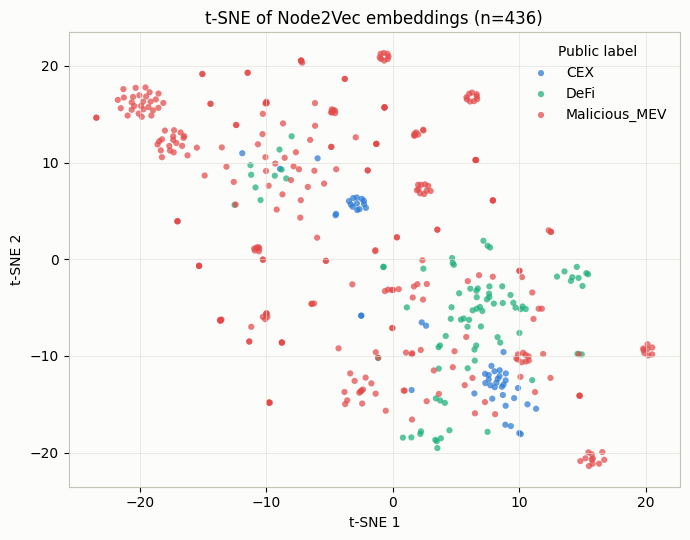

In [4]:
X = seed_embeddings[embedding_columns].to_numpy(dtype=float)
y = seed_embeddings[LABEL_COLUMN].to_numpy()

projection = TSNE(n_components=2, random_state=42, perplexity=30, init="pca").fit_transform(X)
plot_frame = seed_embeddings[["address", LABEL_COLUMN]].copy()
plot_frame[["tsne_x", "tsne_y"]] = projection

fig, ax = plt.subplots(figsize=(7, 5.5))
for label in LABEL_ORDER:
    subset = plot_frame[plot_frame[LABEL_COLUMN] == label]
    ax.scatter(subset["tsne_x"], subset["tsne_y"], s=20, alpha=0.72,
               color=LABEL_COLORS[label], label=label, edgecolors="none")
ax.set(title=f"t-SNE of Node2Vec embeddings (n={len(plot_frame)})", xlabel="t-SNE 1", ylabel="t-SNE 2")
ax.legend(title="Public label", frameon=False)
ax.grid(alpha=0.6)
fig.tight_layout()
plt.show()


## 4. Evaluate KMeans and Louvain alignment

KMeans forms three groups in embedding space. Louvain detects weighted communities on the complete undirected transaction graph and maps the resulting community IDs to labelled nodes. NMI measures shared information, ARI adjusts agreement for chance, and silhouette measures geometric compactness in embedding space.

The permutation test shuffles category labels 2,000 times while retaining each fitted clustering. Its one-sided p-value estimates how often random labels produce equal or stronger agreement.


In [5]:
def permutation_significance(y_true, y_pred, n_permutations=2000, seed=42):
    rng = np.random.default_rng(seed)
    observed_nmi = normalized_mutual_info_score(y_true, y_pred)
    observed_ari = adjusted_rand_score(y_true, y_pred)
    null_nmi = np.empty(n_permutations)
    null_ari = np.empty(n_permutations)
    for index in range(n_permutations):
        shuffled = rng.permutation(y_true)
        null_nmi[index] = normalized_mutual_info_score(shuffled, y_pred)
        null_ari[index] = adjusted_rand_score(shuffled, y_pred)
    return {
        "nmi_observed": observed_nmi,
        "nmi_null_mean": null_nmi.mean(),
        "nmi_null_std": null_nmi.std(),
        "nmi_p_value": (null_nmi >= observed_nmi).mean(),
        "ari_observed": observed_ari,
        "ari_null_mean": null_ari.mean(),
        "ari_null_std": null_ari.std(),
        "ari_p_value": (null_ari >= observed_ari).mean(),
    }

def evaluate_main_clustering(graph, seed_frame, output_dir):
    import community as community_louvain

    output_dir.mkdir(parents=True, exist_ok=True)
    emb_columns = [column for column in seed_frame if column.startswith("emb_")]
    matrix = seed_frame[emb_columns].to_numpy(dtype=float)
    labels = seed_frame[LABEL_COLUMN].to_numpy()

    kmeans_labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(matrix)
    partition = community_louvain.best_partition(graph, weight="weight", random_state=42)
    louvain_labels = seed_frame["address"].map(partition).to_numpy()

    summary = pd.DataFrame([
        {"method": "KMeans", "n_clusters": 3,
         "NMI": normalized_mutual_info_score(labels, kmeans_labels),
         "ARI": adjusted_rand_score(labels, kmeans_labels),
         "Silhouette": silhouette_score(matrix, kmeans_labels)},
        {"method": "Louvain", "n_clusters": len(np.unique(louvain_labels)),
         "NMI": normalized_mutual_info_score(labels, louvain_labels),
         "ARI": adjusted_rand_score(labels, louvain_labels),
         "Silhouette": silhouette_score(matrix, louvain_labels)},
    ]).round(4)
    significance_rows = []
    for method, predictions in [("KMeans", kmeans_labels), ("Louvain", louvain_labels)]:
        row = permutation_significance(labels, predictions)
        row["method"] = method
        significance_rows.append(row)
    significance = pd.DataFrame(significance_rows)[[
        "method", "nmi_observed", "nmi_null_mean", "nmi_null_std", "nmi_p_value",
        "ari_observed", "ari_null_mean", "ari_null_std", "ari_p_value",
    ]].round(4)
    summary.to_csv(output_dir / "clustering_evaluation_summary.csv", index=False)
    significance.to_csv(output_dir / "clustering_significance_test.csv", index=False)
    return summary, significance

if RUN_RETRAINING:
    clustering_summary, clustering_significance = evaluate_main_clustering(G, seed_embeddings, RERUN_DIR)
else:
    clustering_summary = pd.read_csv(RESULT_DIR / "clustering_evaluation_summary.csv")
    clustering_significance = pd.read_csv(RESULT_DIR / "clustering_significance_test.csv")

display(clustering_summary)
display(clustering_significance)


,method,n_clusters,NMI,ARI,Silhouette
0,KMeans,3,0.1632,0.0265,0.1778
1,Louvain,90,0.2185,0.0131,0.3101


,method,nmi_observed,nmi_null_mean,nmi_null_std,nmi_p_value,ari_observed,ari_null_mean,ari_null_std,ari_p_value
0,KMeans,0.1632,0.0053,0.0038,0.0,0.0265,-0.0003,0.0115,0.0195
1,Louvain,0.2185,0.0905,0.0072,0.0,0.0131,-0.0001,0.0056,0.0155


## 5. Check cluster count and density structure

The `k=2...8` scan tests sensitivity to the selected number of KMeans groups. DBSCAN examines density structure across empirical `eps` candidates derived from fifth-nearest-neighbour distances.


,k,silhouette,NMI,ARI
0,2,0.1709,0.1822,0.1716
1,3,0.1778,0.1632,0.0265
2,4,0.1903,0.1597,-0.0606
3,5,0.2034,0.1575,-0.0490
4,6,0.1225,0.1738,0.0385
5,7,0.1383,0.1707,-0.0070
6,8,0.1421,0.1674,0.0167


,eps,n_clusters,noise_ratio,NMI,ARI
0,2.8668,11,0.6697,0.2328,0.0234
1,5.0351,12,0.4312,0.1518,-0.0003
2,8.0213,4,0.2661,0.0549,-0.0855
3,9.3533,1,0.1147,NaN,NaN
4,10.5227,1,0.0390,NaN,NaN
5,11.3673,1,0.0206,NaN,NaN


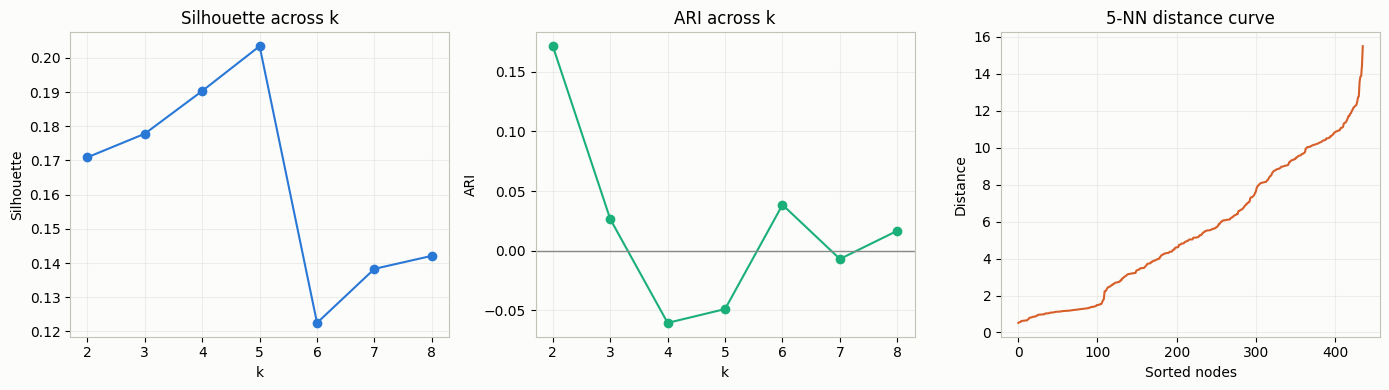

In [6]:
def run_cluster_sensitivity(matrix, labels, output_dir):
    k_rows = []
    for k in range(2, 9):
        predictions = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(matrix)
        k_rows.append({
            "k": k,
            "silhouette": silhouette_score(matrix, predictions),
            "NMI": normalized_mutual_info_score(labels, predictions),
            "ARI": adjusted_rand_score(labels, predictions),
        })
    k_scan = pd.DataFrame(k_rows).round(4)

    scaled = StandardScaler().fit_transform(matrix)
    distances = np.sort(NearestNeighbors(n_neighbors=5).fit(scaled).kneighbors(scaled)[0][:, -1])
    dbscan_rows = []
    for eps in np.percentile(distances, [30, 50, 70, 80, 90, 95]):
        predictions = DBSCAN(eps=eps, min_samples=5).fit_predict(scaled)
        cluster_count = len(set(predictions)) - int(-1 in predictions)
        dbscan_rows.append({
            "eps": eps,
            "n_clusters": cluster_count,
            "noise_ratio": (predictions == -1).mean(),
            "NMI": normalized_mutual_info_score(labels, predictions) if cluster_count >= 2 else np.nan,
            "ARI": adjusted_rand_score(labels, predictions) if cluster_count >= 2 else np.nan,
        })
    dbscan_scan = pd.DataFrame(dbscan_rows).round(4)
    k_scan.to_csv(output_dir / "kmeans_k_scan.csv", index=False)
    dbscan_scan.to_csv(output_dir / "dbscan_eps_scan.csv", index=False)
    return k_scan, dbscan_scan, distances

if RUN_RETRAINING:
    k_scan, dbscan_scan, neighbour_distances = run_cluster_sensitivity(X, y, RERUN_DIR)
else:
    k_scan = pd.read_csv(RESULT_DIR / "kmeans_k_scan.csv")
    dbscan_scan = pd.read_csv(RESULT_DIR / "dbscan_eps_scan.csv")
    scaled = StandardScaler().fit_transform(X)
    neighbour_distances = np.sort(NearestNeighbors(n_neighbors=5).fit(scaled).kneighbors(scaled)[0][:, -1])

display(k_scan)
display(dbscan_scan)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(k_scan["k"], k_scan["silhouette"], marker="o", color="#2a78d6")
axes[0].set(title="Silhouette across k", xlabel="k", ylabel="Silhouette")
axes[1].plot(k_scan["k"], k_scan["ARI"], marker="o", color="#1baf7a")
axes[1].axhline(0, color="#888888", linewidth=1)
axes[1].set(title="ARI across k", xlabel="k", ylabel="ARI")
axes[2].plot(neighbour_distances, color="#d65f2a")
axes[2].set(title="5-NN distance curve", xlabel="Sorted nodes", ylabel="Distance")
for axis in axes:
    axis.grid(alpha=0.5)
fig.tight_layout()
plt.show()


## 6. Repeat class-balanced evaluation

The embedded labelled sample contains 51 CEX, 86 DeFi, and 299 MEV-related addresses. Fifty repeated samples draw 51 addresses from each class. The analysis evaluates a fixed full-sample KMeans solution and a fresh KMeans fit within every balanced sample.


,method,ari_mean,ari_std,ari_p5,ari_p50,ari_p95,ari_min,ari_max,pct_significant_at_0.05
0,"KMeans (fixed full-sample clustering, balanced...",0.1303,0.0338,0.0819,0.1312,0.1880,0.0804,0.2283,1.0
1,KMeans (refit fresh on each balanced subset),0.1551,0.0489,0.0824,0.1544,0.2277,0.0595,0.2839,1.0


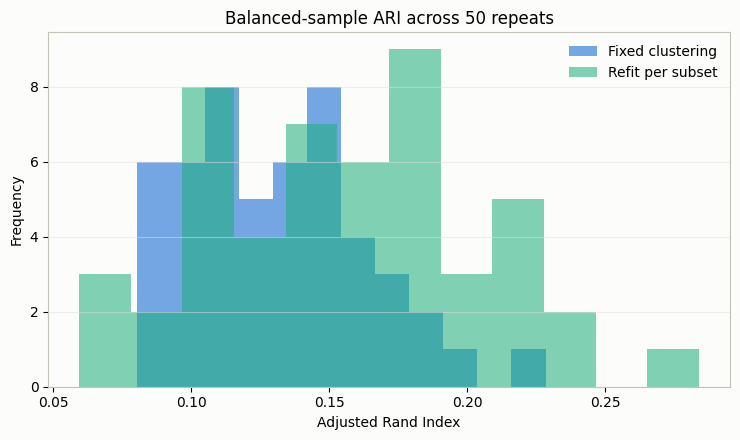

In [7]:
def permutation_ari_p(labels, predictions, seed, n_permutations=500):
    rng = np.random.default_rng(seed)
    observed = adjusted_rand_score(labels, predictions)
    null = np.array([
        adjusted_rand_score(rng.permutation(labels), predictions)
        for _ in range(n_permutations)
    ])
    return observed, (null >= observed).mean()

def run_balanced_ari(seed_frame, output_dir, repeats=50):
    emb_columns = [column for column in seed_frame if column.startswith("emb_")]
    full_matrix = seed_frame[emb_columns].to_numpy(dtype=float)
    fixed_clusters = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(full_matrix)
    working = seed_frame.copy()
    working["fixed_cluster"] = fixed_clusters
    per_class = working[LABEL_COLUMN].value_counts().min()
    repeat_seeds = np.random.default_rng(42).integers(0, 1_000_000, size=repeats)
    rows = []
    for repeat, seed in enumerate(repeat_seeds):
        balanced = working.groupby(LABEL_COLUMN, group_keys=False).apply(
            lambda group: group.sample(n=per_class, random_state=int(seed)), include_groups=True
        )
        fixed_ari, fixed_p = permutation_ari_p(
            balanced[LABEL_COLUMN].to_numpy(), balanced["fixed_cluster"].to_numpy(), int(seed)
        )
        refit_clusters = KMeans(n_clusters=3, random_state=int(seed), n_init=10).fit_predict(
            balanced[emb_columns].to_numpy(dtype=float)
        )
        refit_ari, refit_p = permutation_ari_p(
            balanced[LABEL_COLUMN].to_numpy(), refit_clusters, int(seed)
        )
        rows.append({
            "repeat": repeat, "seed": seed,
            "ari_fixed_clustering_eval": fixed_ari, "p_fixed_clustering_eval": fixed_p,
            "ari_refit_on_subset": refit_ari, "p_refit_on_subset": refit_p,
        })
    runs = pd.DataFrame(rows)
    summary_rows = []
    for method, ari_column, p_column in [
        ("KMeans (fixed full-sample clustering, balanced eval)", "ari_fixed_clustering_eval", "p_fixed_clustering_eval"),
        ("KMeans (refit fresh on each balanced subset)", "ari_refit_on_subset", "p_refit_on_subset"),
    ]:
        values = runs[ari_column]
        summary_rows.append({
            "method": method, "ari_mean": values.mean(), "ari_std": values.std(ddof=0),
            "ari_p5": values.quantile(0.05), "ari_p50": values.quantile(0.50),
            "ari_p95": values.quantile(0.95), "ari_min": values.min(), "ari_max": values.max(),
            "pct_significant_at_0.05": (runs[p_column] < 0.05).mean(),
        })
    summary = pd.DataFrame(summary_rows)
    runs.to_csv(output_dir / "balanced_ari_repeated_runs.csv", index=False)
    summary.round(4).to_csv(output_dir / "balanced_ari_summary.csv", index=False)
    return runs, summary.round(4)

if RUN_RETRAINING:
    balanced_runs, balanced_summary = run_balanced_ari(seed_embeddings, RERUN_DIR)
else:
    balanced_runs = pd.read_csv(RESULT_DIR / "balanced_ari_repeated_runs.csv")
    balanced_summary = pd.read_csv(RESULT_DIR / "balanced_ari_summary.csv")

display(balanced_summary)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.hist(balanced_runs["ari_fixed_clustering_eval"], bins=12, alpha=0.65, label="Fixed clustering", color="#2a78d6")
ax.hist(balanced_runs["ari_refit_on_subset"], bins=12, alpha=0.55, label="Refit per subset", color="#1baf7a")
ax.set(title="Balanced-sample ARI across 50 repeats", xlabel="Adjusted Rand Index", ylabel="Frequency")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.5)
fig.tight_layout()
plt.show()


## 7. Test Node2Vec walk-bias sensitivity

Parameter `p` controls immediate return probability and `q` controls local and outward exploration. Three settings cover unbiased, local-structural, and outward-community walks. Each representation is evaluated with full-sample clustering and repeated balanced samples.


,setting,p,q,n_seeds,kmeans_nmi,kmeans_nmi_p,kmeans_ari,kmeans_ari_p,balanced_ari_mean,balanced_ari_std,balanced_ari_pct_significant
0,"baseline (unbiased, DeepWalk-equivalent)",1.00,1.00,436,0.1672,0.0,0.0412,0.0005,0.1348,0.0350,1.0
1,BFS-like (local/structural),0.25,4.00,436,0.1463,0.0,0.0487,0.0000,0.1214,0.0331,1.0
2,DFS-like (outward/community),4.00,0.25,436,0.1458,0.0,-0.0308,0.9940,0.1029,0.0320,1.0


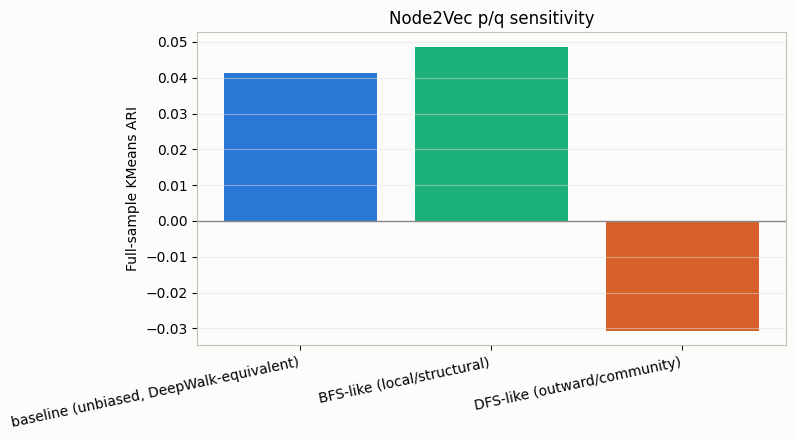

In [8]:
PQ_SETTINGS = [
    ("baseline (unbiased, DeepWalk-equivalent)", 1.0, 1.0),
    ("BFS-like (local/structural)", 0.25, 4.0),
    ("DFS-like (outward/community)", 4.0, 0.25),
]

def balanced_ari_values(frame, clusters, seed, repeats=30, compute_p_values=False):
    evaluation = frame[[LABEL_COLUMN]].copy()
    evaluation["cluster"] = clusters
    per_class = evaluation[LABEL_COLUMN].value_counts().min()
    sample_seeds = np.random.default_rng(seed).integers(0, 1_000_000, size=repeats)
    values = []
    p_values = []
    for sample_seed in sample_seeds:
        balanced = evaluation.groupby(LABEL_COLUMN, group_keys=False).apply(
            lambda group: group.sample(n=per_class, random_state=int(sample_seed)), include_groups=True
        )
        observed = adjusted_rand_score(balanced[LABEL_COLUMN], balanced["cluster"])
        values.append(observed)
        if compute_p_values:
            rng = np.random.default_rng(int(sample_seed))
            null = np.array([
                adjusted_rand_score(rng.permutation(balanced[LABEL_COLUMN]), balanced["cluster"])
                for _ in range(500)
            ])
            p_values.append((null >= observed).mean())
    values = np.asarray(values)
    if compute_p_values:
        return values, np.asarray(p_values)
    return values

def run_pq_sensitivity(graph, feature_frame, output_dir):
    rows = []
    for setting, p, q in PQ_SETTINGS:
        embedding = train_node2vec_embedding(graph, p=p, q=q, seed=42)
        labelled = feature_frame[["address", LABEL_COLUMN, "is_active"]].merge(
            embedding, left_on="address", right_index=True, how="left"
        ).dropna(subset=embedding.columns)
        matrix = labelled[embedding.columns].to_numpy(dtype=float)
        clusters = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(matrix)
        significance = permutation_significance(labelled[LABEL_COLUMN].to_numpy(), clusters)
        balanced, balanced_p_values = balanced_ari_values(
            labelled, clusters, seed=42, repeats=30, compute_p_values=True
        )
        rows.append({
            "setting": setting, "p": p, "q": q, "n_seeds": len(labelled),
            "kmeans_nmi": significance["nmi_observed"], "kmeans_nmi_p": significance["nmi_p_value"],
            "kmeans_ari": significance["ari_observed"], "kmeans_ari_p": significance["ari_p_value"],
            "balanced_ari_mean": balanced.mean(), "balanced_ari_std": balanced.std(),
            "balanced_ari_pct_significant": (balanced_p_values < 0.05).mean(),
        })
    result = pd.DataFrame(rows).round(4)
    result.to_csv(output_dir / "pq_sensitivity_results.csv", index=False)
    return result

if RUN_RETRAINING:
    pq_sensitivity = run_pq_sensitivity(G, features, RERUN_DIR)
else:
    pq_sensitivity = pd.read_csv(RESULT_DIR / "pq_sensitivity_results.csv")

display(pq_sensitivity)
fig, ax = plt.subplots(figsize=(8, 4.5))
positions = np.arange(len(pq_sensitivity))
ax.bar(positions, pq_sensitivity["kmeans_ari"], color=["#2a78d6", "#1baf7a", "#d65f2a"])
ax.axhline(0, color="#888888", linewidth=1)
ax.set_xticks(positions, pq_sensitivity["setting"], rotation=12, ha="right")
ax.set(title="Node2Vec p/q sensitivity", ylabel="Full-sample KMeans ARI")
ax.grid(axis="y", alpha=0.5)
fig.tight_layout()
plt.show()


## 8. Evaluate stability across training seeds

The multi-seed experiment retrains every p/q setting with seeds 42 to 46. Each trained representation receives ten balanced-sample evaluations. The active checkpoint is a completed legacy record with an immutable CSV hash and fixed input hashes.


,check,value,passed
0,mode,legacy_complete_read_only,True
1,row count,15,True
2,checkpoint CSV hash,8AB80948B8FC201B...,True
3,graph input hash,59CECEDA94AF4792...,True
4,feature input hash,F06668FF93425133...,True


,setting,p,q,n_train_seeds,ari_mean_across_seeds,ari_std_across_seeds,ari_min_across_seeds,ari_max_across_seeds
0,"baseline (unbiased, DeepWalk-equivalent)",1.00,1.00,5,0.1394,0.0082,0.1312,0.1531
1,BFS-like (local/structural),0.25,4.00,5,0.1117,0.0082,0.0994,0.1223
2,DFS-like (outward/community),4.00,0.25,5,0.1046,0.0074,0.0949,0.1135


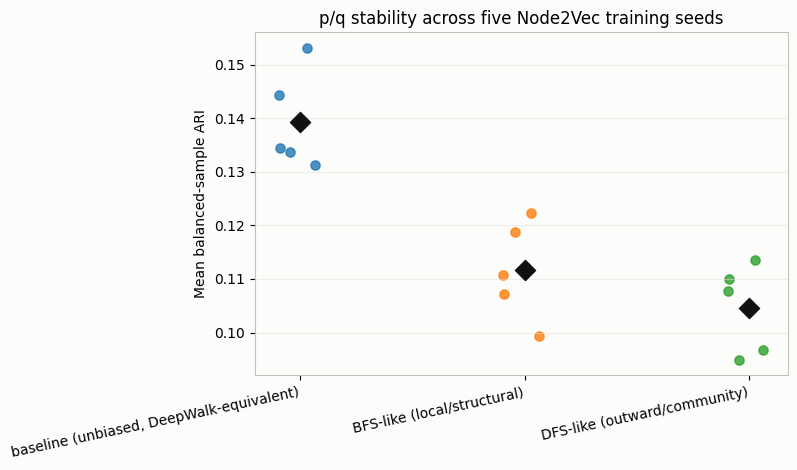

In [9]:
checkpoint_path = RESULT_DIR / "pq_multiseed_checkpoint_metadata.json"
checkpoint = json.loads(checkpoint_path.read_text(encoding="utf-8"))
checkpoint_csv = RESULT_DIR / "pq_multiseed_per_seed.csv"
checkpoint_checks = pd.DataFrame([
    {"check": "mode", "value": checkpoint["mode"], "passed": checkpoint["mode"] == "legacy_complete_read_only"},
    {"check": "row count", "value": checkpoint["checkpoint"]["row_count"], "passed": checkpoint["checkpoint"]["row_count"] == 15},
    {"check": "checkpoint CSV hash", "value": checkpoint["checkpoint"]["csv_sha256"][:16] + "...",
     "passed": checkpoint["checkpoint"]["csv_sha256"] == sha256_file(checkpoint_csv)},
    {"check": "graph input hash", "value": checkpoint["input_hashes"]["graph_sha256"][:16] + "...",
     "passed": checkpoint["input_hashes"]["graph_sha256"] == sha256_file(EDGES_FILE)},
    {"check": "feature input hash", "value": checkpoint["input_hashes"]["feature_sha256"][:16] + "...",
     "passed": checkpoint["input_hashes"]["feature_sha256"] == sha256_file(FEATURE_FILE)},
])
if checkpoint_checks["passed"].eq(False).any():
    raise RuntimeError("The completed multi-seed checkpoint failed validation.")
display(checkpoint_checks)

def run_pq_multiseed(graph, feature_frame, output_dir):
    output_dir.mkdir(parents=True, exist_ok=True)
    train_seeds = [42, 43, 44, 45, 46]
    per_seed_path = output_dir / "pq_multiseed_per_seed.csv"
    rows = []
    for setting, p, q in PQ_SETTINGS:
        for train_seed in train_seeds:
            embedding = train_node2vec_embedding(graph, p=p, q=q, seed=train_seed)
            labelled = feature_frame[["address", LABEL_COLUMN, "is_active"]].merge(
                embedding, left_on="address", right_index=True, how="left"
            ).dropna(subset=embedding.columns)
            matrix = labelled[embedding.columns].to_numpy(dtype=float)
            clusters = KMeans(n_clusters=3, random_state=train_seed, n_init=10).fit_predict(matrix)
            values = balanced_ari_values(labelled, clusters, seed=train_seed, repeats=10)
            rows.append({
                "setting": setting, "p": p, "q": q, "train_seed": train_seed,
                "balanced_ari_mean_over_resamples": values.mean(),
                "balanced_ari_std_over_resamples": values.std(),
            })
            pd.DataFrame(rows).round(4).to_csv(per_seed_path, index=False)
    per_seed = pd.DataFrame(rows).round(4)
    summary_rows = []
    for setting, p, q in PQ_SETTINGS:
        values = per_seed.loc[
            per_seed["setting"] == setting, "balanced_ari_mean_over_resamples"
        ].to_numpy()
        summary_rows.append({
            "setting": setting, "p": p, "q": q, "n_train_seeds": len(values),
            "ari_mean_across_seeds": values.mean(), "ari_std_across_seeds": values.std(),
            "ari_min_across_seeds": values.min(), "ari_max_across_seeds": values.max(),
        })
    summary = pd.DataFrame(summary_rows).round(4)
    summary.to_csv(output_dir / "pq_multiseed_summary.csv", index=False)
    metadata = {
        "mode": "isolated_rerun",
        "input_hashes": {"graph_sha256": sha256_file(EDGES_FILE), "feature_sha256": sha256_file(FEATURE_FILE)},
        "checkpoint": {"row_count": len(per_seed), "csv_sha256": sha256_file(per_seed_path)},
    }
    (output_dir / "pq_multiseed_checkpoint_metadata.json").write_text(
        json.dumps(metadata, indent=2) + "\n", encoding="utf-8"
    )
    return per_seed, summary

if RUN_MULTI_SEED_RETRAINING:
    if RUN_RETRAINING is False:
        raise RuntimeError("Enable RUN_RETRAINING before multi-seed retraining.")
    rerun_multiseed = RERUN_DIR / "pq_multiseed"
    multiseed_runs, multiseed_summary = run_pq_multiseed(G, features, rerun_multiseed)
else:
    multiseed_runs = pd.read_csv(RESULT_DIR / "pq_multiseed_per_seed.csv")
    multiseed_summary = pd.read_csv(RESULT_DIR / "pq_multiseed_summary.csv")

display(multiseed_summary)
fig, ax = plt.subplots(figsize=(8, 4.8))
for position, (setting, group) in enumerate(multiseed_runs.groupby("setting", sort=False)):
    jitter = np.random.default_rng(0).uniform(-0.1, 0.1, len(group))
    ax.scatter(position + jitter, group["balanced_ari_mean_over_resamples"], s=44, alpha=0.8)
    ax.scatter(position, group["balanced_ari_mean_over_resamples"].mean(), marker="D", s=105,
               color="#111111", zorder=4)
ax.set_xticks(range(multiseed_runs["setting"].nunique()), multiseed_runs["setting"].drop_duplicates(), rotation=12, ha="right")
ax.set(title="p/q stability across five Node2Vec training seeds", ylabel="Mean balanced-sample ARI")
ax.grid(axis="y", alpha=0.5)
fig.tight_layout()
plt.show()


## 9. Interpretation and pipeline contribution

1. **Full-sample role alignment is weak.** KMeans reaches ARI 0.0265 and Louvain reaches ARI 0.0131. The public role categories do not form clean unsupervised groups in the reconstructed graph.
2. **Class balance changes the measured alignment.** Repeated balanced evaluation raises mean ARI to 0.1303 for the fixed clustering and 0.1551 for repeated refits. This identifies class imbalance as an important evaluation condition.
3. **Walk-bias conclusions require multi-seed evidence.** Across five training seeds, the unbiased baseline records mean balanced ARI 0.1394, the local-structural setting 0.1117, and the outward-community setting 0.1046.
4. **The embeddings remain useful supervised inputs.** `seed_node2vec_embeddings.csv` supplies the 64 graph-derived features used by `04_supervised/01_traditional_ml/01_classification.ipynb` and `02_repeated_cv.ipynb`.

These findings establish the unsupervised structural baseline for RQ2 and motivate the supervised comparison among engineered features, Node2Vec embeddings, and graph neural network models.
